# Do Sanctions Crash Currencies? The Turkish Lira, 2014 to 2026

**Ibrahim Mansaray** · BSc Mathematics and Physics, University of Warwick

In early 2026 the Iranian rial collapsed. There is no reliable public daily data for the rial (Iran runs several exchange rates at once, and the one most people actually pay is an informal street rate), so I studied the closest liquid analogue: the **Turkish lira**, which was hit by US sanctions and tariffs in 2018, 2019 and 2020, and by a run of home-grown policy shocks in between.

**Research question:** do sanctions crash currencies, and is the crash as bad as the headlines make it look?

**Findings**

1. **Sanctions were triggers, not causes.** Three of the four US sanctions or tariff actions against Turkey moved the lira by less than 5% over two days. The exception, the tariff doubling of 10 August 2018 (+27% in USD/TRY over two days), hit a currency that was already sliding, and it was almost entirely reversed within three months, after the central bank raised rates to 24%.
2. **Home-grown policy shocks did the lasting damage.** Three months after each event, US sanctions had left an average abnormal move of **-2%** in USD/TRY, while domestic policy shocks (sacked central bank governors, rate cuts with inflation near 20%) had left **+9%**. With only 10 events this is suggestive rather than conclusive (Welch test p = 0.09).
3. **The grind beat the crashes.** USD/TRY rose 22-fold between January 2014 and September 2026, so the lira lost 95.5% of its dollar value. Ordinary days multiplied USD/TRY by about 20; the 13 headline weeks together added only 9%, because the panics partly reversed.
4. **Headlines overstate the damage, and normal-distribution risk models understate the risk.** At its worst the August 2018 shock had USD/TRY up 28%; three months later it was up 1%. Meanwhile the lira had **22 days** beyond four standard deviations, where a normal distribution expects **0.2**.

**Contents**
1. Setup
2. Data: ECB reference rates, cross-checked against Yahoo Finance
3. Returns and volatility (and the bug I fixed from my first version)
4. The big picture, 2014 to 2026
5. Two case studies: 2018 and 2021
6. The event catalogue
7. Event study: how big was each shock, and did it last?
8. How long does the panic last?
9. Is it as bad as the headlines say?
10. Crash versus grind: where did the lira's value actually go?
11. Fat tails: why normal-distribution risk models fail here
12. Interactive chart
13. Conclusions, what this means for Iran, and limitations

Appendix: why I did not rely on a GARCH model

## 1. Setup

In [1]:
# Install anything missing (Colab already has most of these)
import importlib.util, subprocess, sys
for pkg in ["arch", "yfinance", "plotly"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from scipy import stats
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Analysis window. START gives a full year of 'normal' history before the first event.
# END is fixed so every number quoted in the README can be reproduced exactly.
START, END = "2014-01-01", "2026-09-14"

DATA_FILE = Path("data/ecb_usdtry.csv")
FIG_DIR, RESULTS_DIR = Path("figures"), Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# One colour per event category, used in every chart (colour-blind-safe set)
COLORS = {
    "US sanctions & tariffs": "#eb6834",
    "Domestic policy shock": "#2a78d6",
    "Lira-supportive policy": "#1baf7a",
}
INK, INK2, NEUTRAL, GRID = "#0b0b0b", "#52514e", "#3d3d3a", "#e6e5e0"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "axes.edgecolor": "#b4b2a9", "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False,
})
print("Libraries imported successfully")

Libraries imported successfully


## 2. Data

My first version downloaded `TRY=X` from Yahoo Finance. For this version the main source is the **European Central Bank's daily euro reference rates**, for three reasons:

* **Official and stable.** The ECB publishes EUR/TRY and EUR/USD every working day from 2005, and the history never changes, so results are exactly reproducible.
* **Yahoo's FX data is thin.** Its `Volume` column for currencies is always zero (you can see this in my first version's output), and its daily bars use a cut-off time that is not documented.
* **Reliability.** `yfinance` is an unofficial scraper that is sometimes rate-limited, which would break the notebook for anyone who clones it.

USD/TRY is built from the two euro rates: lira per dollar = (lira per euro) / (dollars per euro). The ECB takes its rates at about 14:10 CET each day, so each value is a snapshot at that time rather than a "close". A snapshot is saved in `data/` so the notebook runs offline.

In [2]:
ECB_URL = "https://www.ecb.europa.eu/stats/eurofxref/eurofxref-hist.zip"

def load_usdtry(refresh=False):
    # Daily USD/TRY from ECB reference rates. Uses the saved snapshot unless refresh=True.
    if DATA_FILE.exists() and not refresh:
        return pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)
    raw = pd.read_csv(ECB_URL, compression="zip", index_col="Date", parse_dates=True)
    raw = raw.apply(pd.to_numeric, errors="coerce").sort_index()
    data = pd.DataFrame({"EURUSD": raw["USD"], "EURTRY": raw["TRY"]}).dropna()
    data["USDTRY"] = data["EURTRY"] / data["EURUSD"]
    DATA_FILE.parent.mkdir(exist_ok=True)
    data.to_csv(DATA_FILE, float_format="%.6f")
    return data

fx = load_usdtry().loc[START:END]
df = fx[["USDTRY"]].rename(columns={"USDTRY": "Close"})   # same column name as my first version
print(df.head())
print(df.tail())
print(df.shape, "| first:", df.index[0].date(), "| last:", df.index[-1].date())

               Close
Date                
2014-01-02  2.185020
2014-01-03  2.173757
2014-01-06  2.193574
2014-01-07  2.167436
2014-01-08  2.176034
                Close
Date                 
2026-09-08  48.459962
2026-09-09  48.477257
2026-09-10  48.494835
2026-09-11  48.596360
2026-09-14  48.622284
(3250, 1) | first: 2014-01-02 | last: 2026-09-14


### Cross-check against Yahoo Finance

Two independent sources should tell the same story. This cell compares daily and weekly moves. It needs internet access to Yahoo, so it is skipped quietly if Yahoo is unavailable.

In [3]:
import logging
logging.getLogger("yfinance").setLevel(logging.CRITICAL)   # keep the output tidy if Yahoo is unreachable
try:
    import yfinance as yf
    yahoo = yf.download("TRY=X", start=START, end=END, progress=False, auto_adjust=False)
    if yahoo.empty:
        raise RuntimeError("Yahoo returned no data")
    yahoo.columns = yahoo.columns.get_level_values(0)
    daily = pd.concat({"ECB": np.log(df["Close"]).diff(), "Yahoo": np.log(yahoo["Close"]).diff()}, axis=1).dropna()
    weekly = pd.concat({"ECB": df["Close"], "Yahoo": yahoo["Close"]}, axis=1).resample("W-FRI").last()
    weekly = np.log(weekly).diff().dropna()
    print(f"Correlation of daily moves:  {daily.corr().iloc[0, 1]:.3f}  ({len(daily)} days)")
    print(f"Correlation of weekly moves: {weekly.corr().iloc[0, 1]:.3f}  ({len(weekly)} weeks)")
    print(f"Yahoo 'Volume' is zero on every day: {(yahoo['Volume'] == 0).all()}")
    # Daily correlation is lower than weekly because the two sources sample a 24-hour market at
    # different times of day; over a week those timing differences wash out.
except Exception as e:
    print(f"Yahoo cross-check skipped ({type(e).__name__}). Run in Colab with internet access to see it.")

Correlation of daily moves:  0.597  (3245 days)
Correlation of weekly moves: 0.948  (662 weeks)
Yahoo 'Volume' is zero on every day: True


## 3. Returns and volatility

**What changed from my first version.** I originally wrote

```python
df["Volatility"] = df["Close"].rolling(window=21).std() * (252 ** 0.5)
```

That measures how much the **price level** moved around inside each 21-day window, in lira. It is not volatility, and it is why my chart showed "volatility" of about 10. Volatility is the standard deviation of **returns**, which is unit-free and comparable across time and across currencies (a 1-lira wobble means a lot at 3.8 lira per dollar and very little at 48).

The corrected definitions:

* **Log return:** $r_t = \ln(P_t / P_{t-1})$. I use log returns for all statistics because they add up over time (the move over a week is the sum of the daily moves), which the event study and the decomposition in section 10 rely on.
* **Realised volatility (21 trading days, annualised):** $\sigma_t = \text{std}(r_{t-20}, \dots, r_t) \times \sqrt{252}$. The $\sqrt{252}$ comes from variances adding over independent days: a year has about 252 trading days, so annual variance is $252\,\sigma^2_{\text{daily}}$.
* **EWMA volatility** (RiskMetrics, $\lambda = 0.94$): $\sigma^2_t = \lambda\,\sigma^2_{t-1} + (1-\lambda)\,r_t^2$. It reacts to a shock immediately and then decays smoothly, which makes it better for measuring how quickly panic fades (section 8).

A sign convention to keep straight: **USD/TRY going up means the lira is getting weaker.**

In [4]:
df["Return"] = df["Close"].pct_change()                                  # simple return (as in my first version)
df["LogReturn"] = np.log(df["Close"]).diff()                             # used for all statistics
df["Volatility"] = df["LogReturn"].rolling(21).std() * np.sqrt(252)      # fixed: std of returns, not prices
df["EWMAVol"] = np.sqrt((df["LogReturn"] ** 2).ewm(alpha=1 - 0.94, adjust=False).mean() * 252)
r = df["LogReturn"].dropna()

v1 = df["Close"].rolling(21).std() * np.sqrt(252)    # my first version, kept only for comparison
aug18 = slice("2018-08-01", "2018-09-30")
print(f"Peak 'volatility' Aug-Sep 2018, first version: {v1.loc[aug18].max():.1f}  <- units of lira, not meaningful")
print(f"Peak volatility Aug-Sep 2018, corrected:       {df['Volatility'].loc[aug18].max():.0%} a year")
print(f"Typical (median) volatility 2014-2026:         {df['Volatility'].median():.0%} a year")

Peak 'volatility' Aug-Sep 2018, first version: 10.3  <- units of lira, not meaningful
Peak volatility Aug-Sep 2018, corrected:       76% a year
Typical (median) volatility 2014-2026:         9% a year


## 4. The big picture, 2014 to 2026

The coloured lines mark the 13 events studied in section 6 onwards.

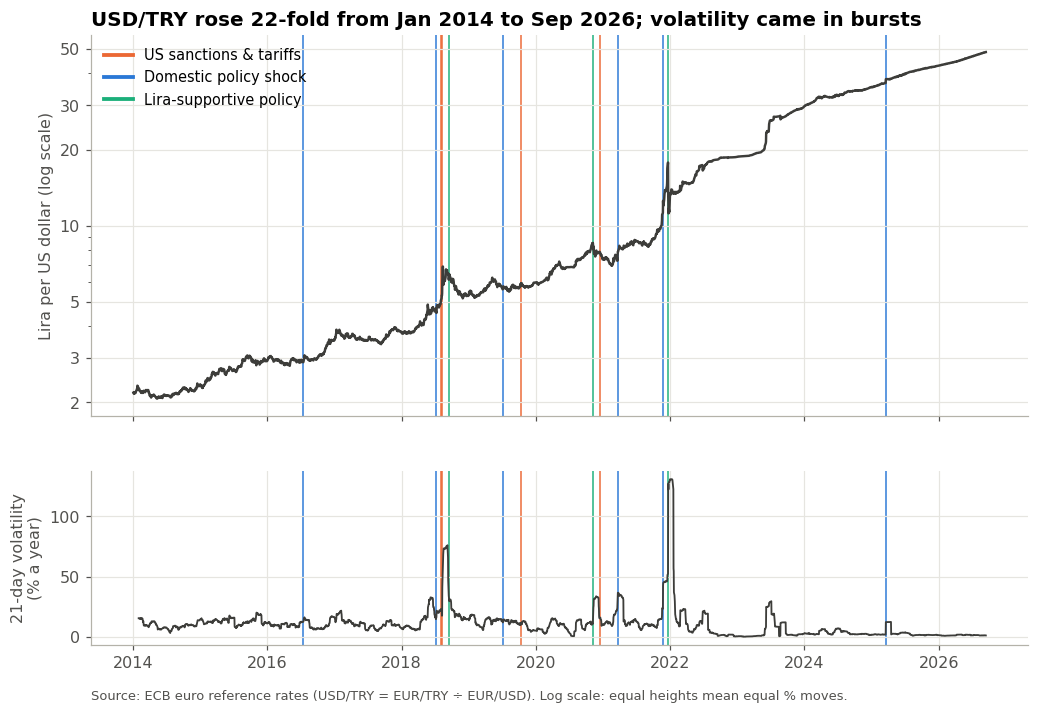

In [5]:
# Event catalogue (sources in section 6). Day 0 is the first ECB fixing on or after the date.
events = pd.DataFrame([
    ("2016-07-15", "Coup attempt", "Domestic policy shock",
     "Failed military coup attempt on a Friday night", "https://en.wikipedia.org/wiki/2016_Turkish_coup_attempt"),
    ("2018-07-09", "Albayrak made finance minister", "Domestic policy shock",
     "Erdoğan appoints his son-in-law to run the economy under new presidential powers",
     "https://www.cnbc.com/2018/07/09/turkeys-erdogan-names-son-in-law-finance-minister-in-new-cabinet.html"),
    ("2018-08-01", "US sanctions two ministers", "US sanctions & tariffs",
     "US Treasury sanctions the justice and interior ministers over the detention of pastor Andrew Brunson",
     "https://www.aljazeera.com/amp/news/2018/8/1/us-sanctions-two-turkey-officials-over-detention-of-pastor"),
    ("2018-08-10", "US doubles metal tariffs", "US sanctions & tariffs",
     "Trump doubles tariffs on Turkish steel (to 50%) and aluminium (to 20%)",
     "https://www.mprnews.org/story/2018/08/10/npr-trump-doubles-tariffs-on-steel-aluminum-from-turkey"),
    ("2018-09-13", "CBRT hikes to 24%", "Lira-supportive policy",
     "Central bank raises its policy rate by 625bp, from 17.75% to 24%",
     "https://www.cnbc.com/2018/09/13/lira-jumps-as-turkish-central-bank-hikes-rates-to-24-percent.html"),
    ("2019-07-06", "Governor Çetinkaya sacked", "Domestic policy shock",
     "Central bank governor removed by presidential decree on a Saturday",
     "https://www.cnbc.com/2019/07/06/turkey-fires-central-bank-governor-as-policy-differences-deepen.html"),
    ("2019-10-14", "US sanctions ministries (Syria)", "US sanctions & tariffs",
     "US sanctions the defence and energy ministries and three ministers over the Syria offensive; steel tariff back to 50%",
     "https://www.dailysabah.com/economy/2019/10/14/markets-stable-as-trump-announces-new-tariffs-on-turkey/amp"),
    ("2020-11-07", "Governor Uysal out, Albayrak quits", "Lira-supportive policy",
     "Governor removed and the finance minister resigns over a weekend; markets expect a return to orthodox policy",
     "https://www.aljazeera.com/economy/2020/11/9/turkeys-lira-surges-on-finance-minister-central-bank-shake-up"),
    ("2020-12-14", "US CAATSA sanctions on SSB", "US sanctions & tariffs",
     "US sanctions Turkey's defence procurement agency over the Russian S-400 purchase",
     "https://www.everycrsreport.com/reports/IN11557.html"),
    ("2021-03-20", "Governor Ağbal sacked", "Domestic policy shock",
     "Governor removed two days after raising rates 200bp to 19%; replaced by a critic of high rates",
     "https://sharecast.com/news/international-economic/turkish-lira-drops-after-erdogan-sacks-central-bank-chief--7847931.html"),
    ("2021-11-22", "Erdoğan defends rate cuts", "Domestic policy shock",
     "Erdoğan backs further rate cuts as an 'economic war of independence' with inflation near 20% and the policy rate at 15%",
     "https://www.businesstoday.in/amp/latest/story/turkish-lira-crashes-by-15-after-president-erdogan-defends-sharp-rate-cuts-313160-2021-11-23"),
    ("2021-12-20", "FX-protected deposits (KKM)", "Lira-supportive policy",
     "State promises to compensate lira savers for any depreciation (the 'KKM' scheme)",
     "https://www.bloomberg.com/news/articles/2021-12-20/erdogan-unveils-extraordinary-steps-to-protect-lira-savings"),
    ("2025-03-19", "İmamoğlu detained", "Domestic policy shock",
     "Istanbul mayor and main opposition figure detained in a pre-dawn raid",
     "https://europeancapitalinsights.substack.com/p/turkey-ignites-protests-lira-freefall"),
], columns=["date", "short", "category", "description", "source"])
events["date"] = pd.to_datetime(events["date"])
events["day0"] = [df.index[df.index.searchsorted(d)] for d in events["date"]]

def category_legend(ax, loc="upper left", extra=(), cats=None, **kw):
    handles = [Line2D([0], [0], color=c, lw=2.5, label=k) for k, c in COLORS.items() if cats is None or k in cats]
    ax.legend(handles=list(extra) + handles, loc=loc, fontsize=9.5, **kw)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax1.plot(df.index, df["Close"], color=NEUTRAL, lw=1.6)
ax1.set_yscale("log")
ax1.set_yticks([2, 3, 5, 10, 20, 30, 50])
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax1.yaxis.set_minor_formatter(mticker.NullFormatter())
ax1.set_ylabel("Lira per US dollar (log scale)")
growth = df["Close"].iloc[-1] / df["Close"].iloc[0]
ax1.set_title(f"USD/TRY rose {growth:.0f}-fold from {df.index[0]:%b %Y} to {df.index[-1]:%b %Y}; volatility came in bursts")
ax2.plot(df.index, df["Volatility"] * 100, color=NEUTRAL, lw=1.2)
ax2.set_ylabel("21-day volatility\n(% a year)")
for _, ev in events.iterrows():
    for ax in (ax1, ax2):
        ax.axvline(ev["day0"], color=COLORS[ev["category"]], lw=1.3, alpha=0.75, zorder=0)
category_legend(ax1)
ax2.text(0.0, -0.32, "Source: ECB euro reference rates (USD/TRY = EUR/TRY ÷ EUR/USD). Log scale: equal heights mean equal % moves.",
         transform=ax2.transAxes, fontsize=8.5, color=INK2)
fig.savefig(FIG_DIR / "01_big_picture.png")
plt.show()

## 5. Two case studies: 2018 and 2021

These are the two charts from my first version, rebuilt as one reusable function (instead of copying the plotting code for each period) and extended to show the price itself and every event in the window.

* **2018** is the "sanctions" crisis: US sanctions on 1 August and doubled tariffs on 10 August, followed by the central bank's 625bp rate hike on 13 September.
* **2021** is a crisis with **no sanctions at all**: the governor was sacked in March, then rates were cut while inflation was near 20%, until the state stepped in with the KKM deposit guarantee in December.

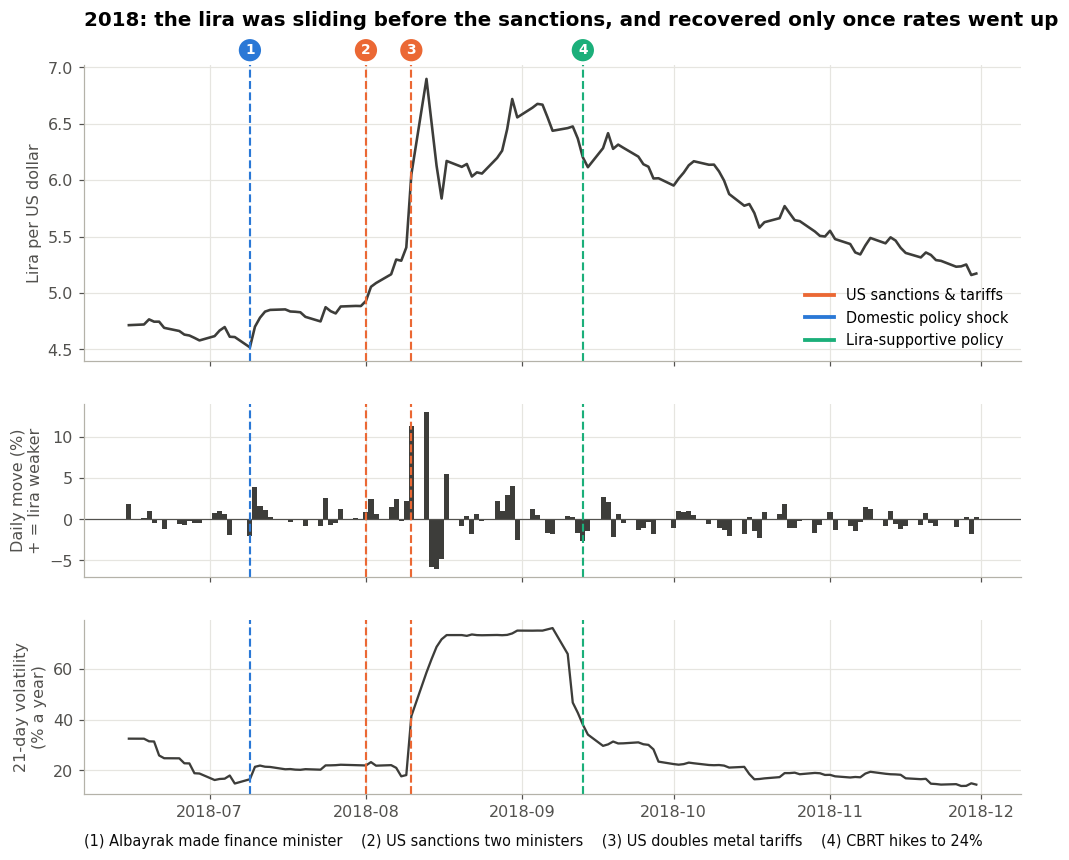

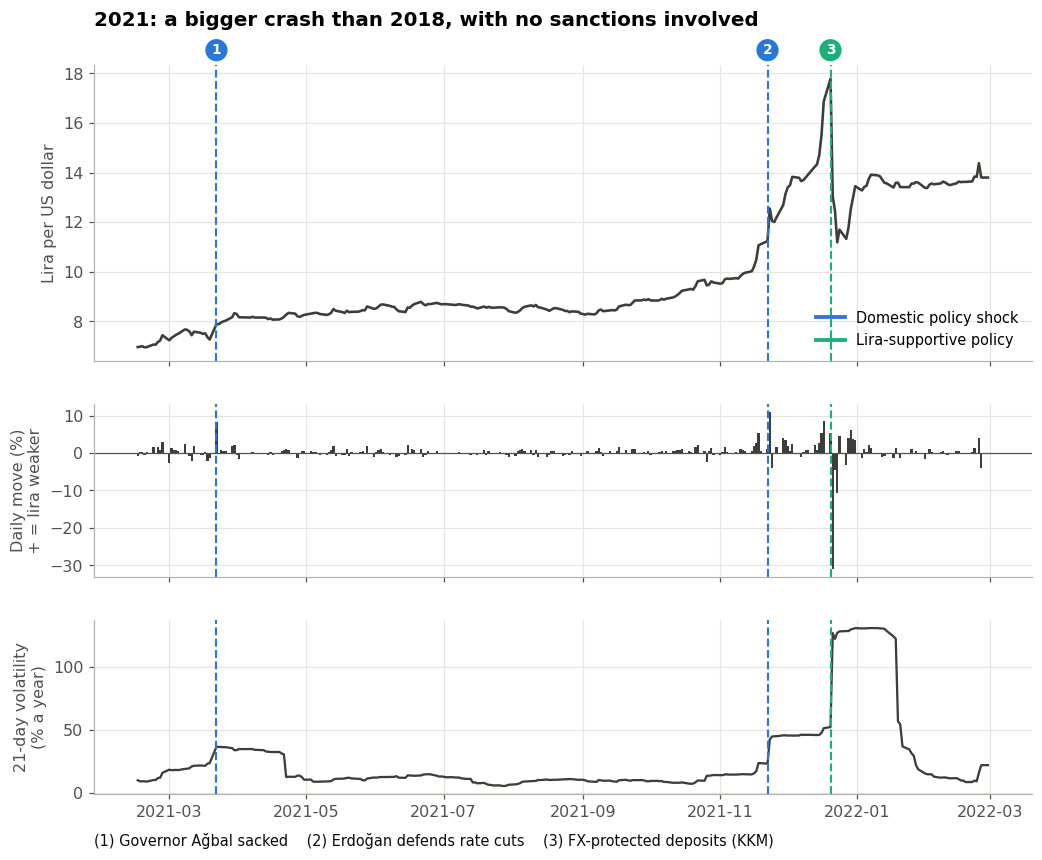

In [6]:
def plot_case_study(start, end, title, fname):
    w = df.loc[start:end]
    evs = events[(events["day0"] >= start) & (events["day0"] <= end)]
    fig, axes = plt.subplots(3, 1, figsize=(11, 8.6), sharex=True, gridspec_kw={"height_ratios": [1.7, 1, 1]})
    axes[0].plot(w.index, w["Close"], color=NEUTRAL, lw=1.7)
    axes[0].set_ylabel("Lira per US dollar")
    axes[1].bar(w.index, w["LogReturn"] * 100, width=1.0, color=NEUTRAL)
    axes[1].axhline(0, color=INK2, lw=0.8)
    axes[1].set_ylabel("Daily move (%)\n+ = lira weaker")
    axes[2].plot(w.index, w["Volatility"] * 100, color=NEUTRAL, lw=1.5)
    axes[2].set_ylabel("21-day volatility\n(% a year)")
    for k, (_, ev) in enumerate(evs.iterrows(), start=1):
        c = COLORS[ev["category"]]
        for ax in axes:
            ax.axvline(ev["day0"], color=c, ls="--", lw=1.4)
        axes[0].annotate(str(k), xy=(ev["day0"], 1.0), xycoords=("data", "axes fraction"), xytext=(0, 10),
                         textcoords="offset points", ha="center", va="center", fontsize=9, fontweight="bold",
                         color="white", bbox=dict(boxstyle="circle,pad=0.3", fc=c, ec="none"))
    key = "    ".join(f"({k}) {s}" for k, s in enumerate(evs["short"], start=1))
    axes[-1].text(0, -0.3, key, transform=axes[-1].transAxes, fontsize=9.5, color=INK)
    axes[0].set_title(title, pad=26)
    category_legend(axes[0], loc="lower right", cats=set(evs["category"]))
    fig.savefig(FIG_DIR / fname)
    plt.show()

plot_case_study("2018-06-15", "2018-11-30",
                "2018: the lira was sliding before the sanctions, and recovered only once rates went up",
                "02_case_2018.png")
plot_case_study("2021-02-15", "2022-02-28",
                "2021: a bigger crash than 2018, with no sanctions involved",
                "03_case_2021.png")

My original `move_around` function, upgraded: it now uses trading days (not calendar days), the corrected volatility, and reports the move from the lira's side as well, because "USD/TRY up 25%" and "lira down 25%" are not the same thing (section 9).

In [7]:
def move_around(date, days=10):
    # Summarise the market from `days` trading days before an event to `days` after.
    i0 = df.index.searchsorted(pd.Timestamp(date))
    window = df.iloc[max(i0 - days, 0): i0 + days + 1]
    top_vol = window["Volatility"].max()
    usdtry_change = window["Close"].iloc[-1] / window["Close"].iloc[0] - 1
    lira_change = window["Close"].iloc[0] / window["Close"].iloc[-1] - 1
    print(f"{pd.Timestamp(date).date()} (+/-{days} days): peak vol {top_vol:5.0%} a year | "
          f"USD/TRY {usdtry_change:+6.1%} | lira's dollar value {lira_change:+6.1%}")

move_around("2018-08-10")
move_around("2021-03-20")
move_around("2021-11-22", 20)

2018-08-10 (+/-10 days): peak vol   74% a year | USD/TRY +24.1% | lira's dollar value -19.4%
2021-03-20 (+/-10 days): peak vol   37% a year | USD/TRY  +6.6% | lira's dollar value  -6.2%
2021-11-22 (+/-20 days): peak vol   52% a year | USD/TRY +83.8% | lira's dollar value -45.6%


## 6. The event catalogue

To test whether sanctions matter more than other shocks, I need a set of comparable events chosen **in advance from the news record, not by looking for big moves in the data** (picking the biggest days and then explaining them would guarantee a dramatic answer). The 13 events fall into three groups:

* **US sanctions & tariffs (4):** every major US sanctions or tariff action against Turkey in the period.
* **Domestic policy shocks (6):** events that damaged confidence in Turkish policy or institutions.
* **Lira-supportive policy (3):** events where policy moved to defend the lira. These act as a control: if the method works, they should show moves in the other direction.

Timing rule: day 0 is the first ECB fixing (about 14:10 CET) on or after the event date. Several events happened after that time or at a weekend, so the reaction shows up on day 1. That is why the shortest window I use is days 0 to 1.

In [8]:
catalogue = events[["date", "day0", "category", "description", "source"]].copy()
catalogue["date"] = catalogue["date"].dt.date
catalogue["day0"] = catalogue["day0"].dt.date
catalogue

,date,day0,category,description,source
0,2016-07-15,2016-07-15,Domestic policy shock,Failed military coup attempt on a Friday night,https://en.wikipedia.org/wiki/2016_Turkish_cou...
1,2018-07-09,2018-07-09,Domestic policy shock,Erdoğan appoints his son-in-law to run the eco...,https://www.cnbc.com/2018/07/09/turkeys-erdoga...
2,2018-08-01,2018-08-01,US sanctions & tariffs,US Treasury sanctions the justice and interior...,https://www.aljazeera.com/amp/news/2018/8/1/us...
3,2018-08-10,2018-08-10,US sanctions & tariffs,Trump doubles tariffs on Turkish steel (to 50%...,https://www.mprnews.org/story/2018/08/10/npr-t...
4,2018-09-13,2018-09-13,Lira-supportive policy,"Central bank raises its policy rate by 625bp, ...",https://www.cnbc.com/2018/09/13/lira-jumps-as-...
5,2019-07-06,2019-07-08,Domestic policy shock,Central bank governor removed by presidential ...,https://www.cnbc.com/2019/07/06/turkey-fires-c...
6,2019-10-14,2019-10-14,US sanctions & tariffs,US sanctions the defence and energy ministries...,https://www.dailysabah.com/economy/2019/10/14/...
7,2020-11-07,2020-11-09,Lira-supportive policy,Governor removed and the finance minister resi...,https://www.aljazeera.com/economy/2020/11/9/tu...
8,2020-12-14,2020-12-14,US sanctions & tariffs,US sanctions Turkey's defence procurement agen...,https://www.everycrsreport.com/reports/IN11557...
9,2021-03-20,2021-03-22,Domestic policy shock,Governor removed two days after raising rates ...,https://sharecast.com/news/international-econo...


## 7. Event study: how big was each shock, and did it last?

An **event study** asks how much a price moved *beyond what it would normally have done*. The lira was depreciating steadily throughout the period, so a 2% weaker lira in a week is not news in itself.

For each event:

1. **Normal behaviour** is estimated from trading days $-250$ to $-21$ before the event (about a year, stopping a month short so the run-up to the event does not contaminate it): mean daily return $\mu$ and daily volatility $\sigma$.
2. **Abnormal return** on each day: $AR_t = r_t - \mu$.
3. **Cumulative abnormal return** over a window: $CAR(0, h) = \sum_{t=0}^{h} AR_t$.
4. **Size relative to normal noise:** $z = CAR(0,h) \,/\, (\sigma \sqrt{h+1})$. A $z$ of 5 means the move was five times larger than a typical move over that many days.

I look at three horizons: days 0 to 1 (the immediate reaction), 0 to 5 (the first week) and 0 to 60 (about three months later). CARs are computed in log terms and shown as ordinary percentage moves in USD/TRY, so **positive = lira weaker**.

In [9]:
EST_START, EST_END = -250, -21     # estimation window, in trading days relative to day 0
HORIZONS = (1, 5, 60)

def event_study(returns, event_date):
    i0 = returns.index.searchsorted(pd.Timestamp(event_date))
    est = returns.iloc[i0 + EST_START: i0 + EST_END + 1]
    mu, sigma = est.mean(), est.std()
    abnormal = returns.iloc[i0: i0 + max(HORIZONS) + 1] - mu
    out = {"day0": returns.index[i0], "normal_vol": sigma * np.sqrt(252)}
    for h in HORIZONS:
        car = abnormal.iloc[: h + 1].sum()
        out[f"car_{h}"] = car                              # log terms (adds up)
        out[f"move_{h}"] = np.expm1(car) * 100            # ordinary % move in USD/TRY
        out[f"z_{h}"] = car / (sigma * np.sqrt(h + 1))
    cum20 = abnormal.iloc[:21].cumsum()
    out["move_peak20"] = np.expm1(cum20.loc[cum20.abs().idxmax()]) * 100   # largest abnormal move in first month
    return out

results = pd.concat([events[["date", "short", "category"]],
                     pd.DataFrame([event_study(r, d) for d in events["date"]])], axis=1)

show = results[["date", "short", "category", "normal_vol", "move_1", "z_1", "move_5", "move_peak20", "move_60"]].copy()
show["date"] = show["date"].dt.date
show["normal_vol"] = (show["normal_vol"] * 100).round(0)
show.columns = ["Date", "Event", "Category", "Normal vol before (% a yr)", "Days 0-1 (%)", "z (days 0-1)",
                "Days 0-5 (%)", "Peak in first month (%)", "Days 0-60 (%)"]
show.round(1)

,Date,Event,Category,Normal vol before (% a yr),Days 0-1 (%),z (days 0-1),Days 0-5 (%),Peak in first month (%),Days 0-60 (%)
0,2016-07-15,Coup attempt,Domestic policy shock,12.0,2.3,2.2,5.3,6.2,3.8
1,2018-07-09,Albayrak made finance minister,Domestic policy shock,14.0,1.8,1.5,4.7,9.7,21.5
2,2018-08-01,US sanctions two ministers,US sanctions & tariffs,14.0,3.2,2.5,7.4,39.7,8.5
3,2018-08-10,US doubles metal tariffs,US sanctions & tariffs,15.0,27.3,18.0,13.3,27.3,-6.7
4,2018-09-13,CBRT hikes to 24%,Lira-supportive policy,26.0,-4.5,-2.0,-2.3,-10.6,-27.4
5,2019-07-06,Governor Çetinkaya sacked,Domestic policy shock,28.0,1.5,0.6,1.2,-2.9,-4.2
6,2019-10-14,US sanctions ministries (Syria),US sanctions & tariffs,14.0,0.3,0.2,-0.7,-3.0,-0.1
7,2020-11-07,"Governor Uysal out, Albayrak quits",Lira-supportive policy,9.0,-3.5,-4.3,-10.0,-12.7,-22.9
8,2020-12-14,US CAATSA sanctions on SSB,US sanctions & tariffs,13.0,-0.7,-0.6,-3.3,-8.9,-10.3
9,2021-03-20,Governor Ağbal sacked,Domestic policy shock,14.0,8.4,6.4,12.2,14.4,15.4


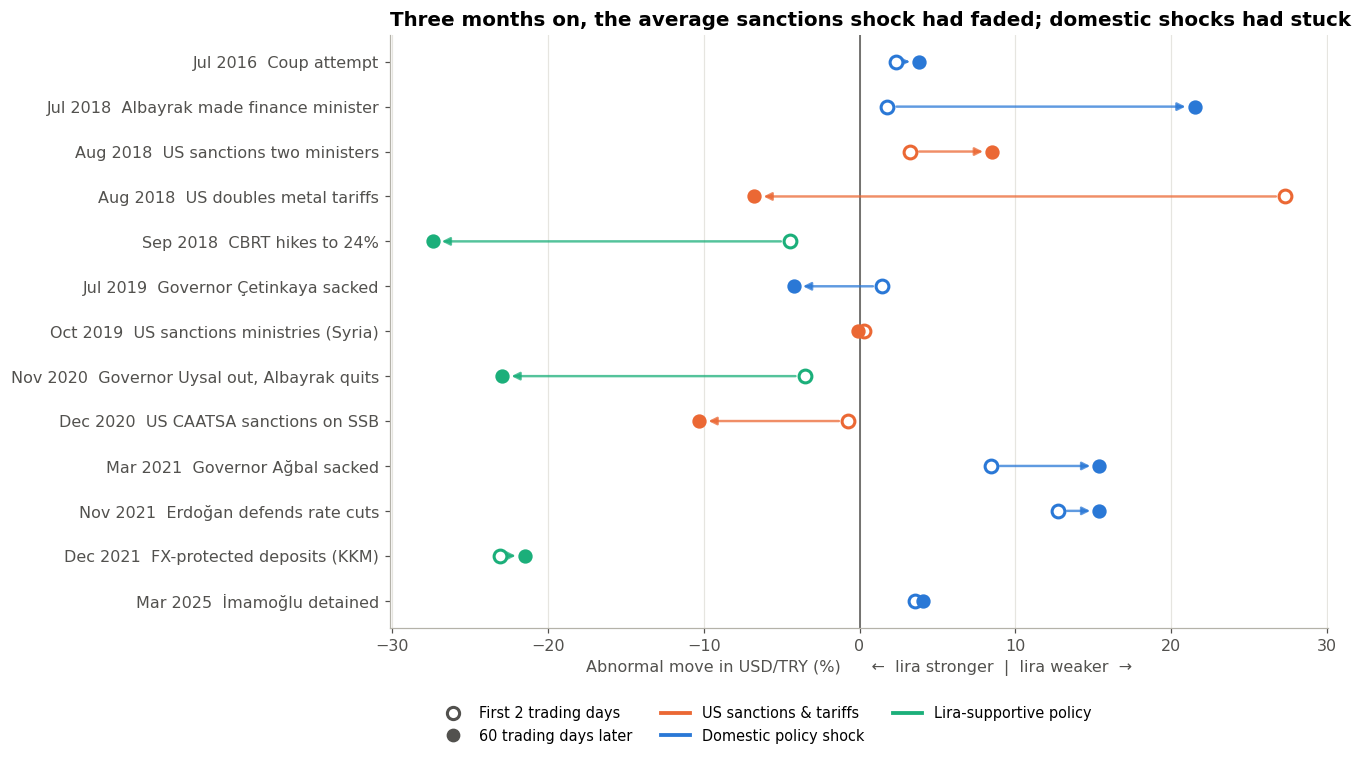

In [10]:
order = results.sort_values("date", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 7))
for y, row in order.iterrows():
    c = COLORS[row["category"]]
    ax.annotate("", xy=(row["move_60"], y), xytext=(row["move_1"], y),
                arrowprops=dict(arrowstyle="-|>", color=c, lw=1.6, alpha=0.75, shrinkA=6, shrinkB=6))
    ax.scatter(row["move_1"], y, s=70, facecolor="white", edgecolor=c, lw=2, zorder=3)
    ax.scatter(row["move_60"], y, s=70, color=c, zorder=3)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{d:%b %Y}  {s}" for d, s in zip(order["date"], order["short"])])
ax.axvline(0, color=INK2, lw=1)
ax.set_xlabel("Abnormal move in USD/TRY (%)      ←  lira stronger  |  lira weaker  →")
ax.grid(axis="y", visible=False)
ax.set_title("Three months on, the average sanctions shock had faded; domestic shocks had stuck")
markers = [Line2D([0], [0], marker="o", ls="", markerfacecolor="white", markeredgecolor=INK2, mew=2, ms=8, label="First 2 trading days"),
           Line2D([0], [0], marker="o", ls="", color=INK2, ms=8, label="60 trading days later")]
category_legend(ax, loc="upper center", extra=markers, bbox_to_anchor=(0.4, -0.11), ncol=3)
fig.savefig(FIG_DIR / "04_event_study.png")
plt.show()

### Do the groups differ?

Averages by group, and a test of whether the three-month effect of US sanctions differs from that of domestic policy shocks. With only 4 and 6 events, the test has little power, so a p-value around 0.1 should be read as *suggestive*, not proven.

In [11]:
summary = results.groupby("category").agg(
    events=("short", "count"),
    median_move_1=("move_1", "median"), mean_move_1=("move_1", "mean"),
    median_move_60=("move_60", "median"), mean_move_60=("move_60", "mean"),
).round(1)
print(summary, "\n")

sanc = results.loc[results["category"] == "US sanctions & tariffs", "car_60"]
dom = results.loc[results["category"] == "Domestic policy shock", "car_60"]
welch = stats.ttest_ind(sanc, dom, equal_var=False)
mw = stats.mannwhitneyu(sanc, dom)
print(f"60-day abnormal move, sanctions vs domestic shocks: Welch t = {welch.statistic:.2f}, p = {welch.pvalue:.3f}; "
      f"Mann-Whitney p = {mw.pvalue:.3f}")
small_sanctions = results[(results["category"] == "US sanctions & tariffs") & (results["move_1"].abs() < 5)]
print(f"US sanctions/tariff events with a 2-day move under 5%: {len(small_sanctions)} of {len(sanc)}")

                        events  median_move_1  mean_move_1  median_move_60  mean_move_60
category                                                                                
Domestic policy shock        6            2.9          5.0             9.7           9.3
Lira-supportive policy       3           -4.5        -10.3           -22.9         -23.9
US sanctions & tariffs       4            1.8          7.5            -3.4          -2.1 

60-day abnormal move, sanctions vs domestic shocks: Welch t = -1.99, p = 0.087; Mann-Whitney p = 0.114
US sanctions/tariff events with a 2-day move under 5%: 3 of 4


## 8. How long does the panic last?

For each event that hit the lira, I take the EWMA volatility the day before (the baseline), its peak in the following month, and count the trading days from the peak until volatility has fallen **halfway back** to the baseline: an empirical "half-life" of the panic.

In [12]:
def vol_half_life(date):
    i0 = df.index.searchsorted(pd.Timestamp(date))
    base = df["EWMAVol"].iloc[i0 - 1]
    window = df["EWMAVol"].iloc[i0: i0 + 21]
    k = int(np.argmax(window.values))
    peak = window.iloc[k]
    after = df["EWMAVol"].iloc[i0 + k:]
    halfway = base + 0.5 * (peak - base)
    hit = np.where(after.values <= halfway)[0]
    spiked = peak >= 1.2 * base                      # ignore events with no real volatility spike
    return pd.Series({"vol_before": base * 100, "vol_peak": peak * 100,
                      "days_to_halve": hit[0] if (spiked and len(hit)) else np.nan})

hl = events[["date", "short", "category"]].join(events["date"].apply(vol_half_life))
hl = hl[hl["category"] != "Lira-supportive policy"]
hl["date"] = hl["date"].dt.date
print(hl.round(0).to_string(index=False, na_rep="no spike"))
print(f"\nMedian days for the panic to halve, where there was a spike: {hl['days_to_halve'].median():.0f} trading days")

      date                           short               category  vol_before  vol_peak  days_to_halve
2016-07-15                    Coup attempt  Domestic policy shock        11.0      15.0            9.0
2018-07-09  Albayrak made finance minister  Domestic policy shock        20.0      25.0            5.0
2018-08-01      US sanctions two ministers US sanctions & tariffs        20.0      74.0           20.0
2018-08-10        US doubles metal tariffs US sanctions & tariffs        23.0      74.0           18.0
2019-07-06       Governor Çetinkaya sacked  Domestic policy shock        13.0      15.0       no spike
2019-10-14 US sanctions ministries (Syria) US sanctions & tariffs        12.0      14.0       no spike
2020-12-14      US CAATSA sanctions on SSB US sanctions & tariffs        21.0      20.0       no spike
2021-03-20           Governor Ağbal sacked  Domestic policy shock        21.0      38.0           11.0
2021-11-22       Erdoğan defends rate cuts  Domestic policy shock        

## 9. Is it as bad as the headlines say?

Two ways headlines overstate a currency crash:

**1. Percentage arithmetic.** If USD/TRY rises by $x$, the lira's dollar value changes by $\frac{1}{1+x} - 1$. "The dollar is up 100% against the lira" means the lira has lost **50%**, not 100%. Reports often mix the two.

**2. Peak versus settled.** News is written at the worst moment. The table compares the worst level within a month of each event with the level three months later (raw prices, as a reader of the news would see them).

In [13]:
def lira_value_change(usdtry_change):
    return 1 / (1 + usdtry_change) - 1

for x in [0.10, 0.25, 0.50, 1.00, 3.00]:
    print(f"USD/TRY up {x:>5.0%}  ->  lira loses {-lira_value_change(x):.0%} of its dollar value")
total = df["Close"].iloc[-1] / df["Close"].iloc[0] - 1
print(f"\nWhole sample: USD/TRY up {total:.0%} ({df['Close'].iloc[0]:.2f} -> {df['Close'].iloc[-1]:.2f}), "
      f"so the lira lost {-lira_value_change(total):.1%} of its dollar value")

rows = []
for _, ev in events[events["category"] != "Lira-supportive policy"].iterrows():
    i0 = df.index.searchsorted(ev["date"])
    before = df["Close"].iloc[i0 - 1]
    peak = df["Close"].iloc[i0: i0 + 21].max()
    later = df["Close"].iloc[i0 + 60]
    if peak / before - 1 < 0.05:
        continue                                     # only events that produced a 5%+ headline move
    rows.append({"Event": f"{ev['date']:%b %Y} {ev['short']}", "Headline peak (%)": (peak / before - 1) * 100,
                 "3 months later (%)": (later / before - 1) * 100,
                 "Share of peak reversed (%)": (1 - np.log(later / before) / np.log(peak / before)) * 100})
headlines = pd.DataFrame(rows).round(1)
headlines   # negative 'share reversed' = the lira kept falling after the first month

USD/TRY up   10%  ->  lira loses 9% of its dollar value
USD/TRY up   25%  ->  lira loses 20% of its dollar value
USD/TRY up   50%  ->  lira loses 33% of its dollar value
USD/TRY up  100%  ->  lira loses 50% of its dollar value
USD/TRY up  300%  ->  lira loses 75% of its dollar value

Whole sample: USD/TRY up 2125% (2.19 -> 48.62), so the lira lost 95.5% of its dollar value


,Event,Headline peak (%),3 months later (%),Share of peak reversed (%)
0,Jul 2016 Coup attempt,6.4,5.6,11.4
1,Jul 2018 Albayrak made finance minister,12.1,29.1,-124.3
2,Aug 2018 US sanctions two ministers,41.2,16.8,54.9
3,Aug 2018 US doubles metal tariffs,27.7,1.4,94.4
4,Mar 2021 Governor Ağbal sacked,14.7,17.7,-18.7
5,Nov 2021 Erdoğan defends rate cuts,60.0,22.1,57.6


## 10. Crash versus grind: where did the lira's value actually go?

Because log returns add up, the total move from the first day to the last can be split exactly into the days inside each event's first week (days 0 to 5) and every other day. Each piece becomes a **multiplier** on USD/TRY, and the multipliers multiply to the total.

In [14]:
day_type = pd.Series("Ordinary days", index=r.index)
for _, ev in events.sort_values("date").iterrows():
    i0 = r.index.searchsorted(ev["date"])
    week = r.index[i0: i0 + 6]
    free = day_type.loc[week] == "Ordinary days"            # never count a day twice
    day_type.loc[week[free.values]] = ev["category"]

contrib = r.groupby(day_type).sum()
n_days = day_type.value_counts()
steps = ["Ordinary days", "US sanctions & tariffs", "Domestic policy shock", "Lira-supportive policy"]
decomp = pd.DataFrame({"days": n_days.reindex(steps), "log_contribution": contrib.reindex(steps)})
decomp["multiplier"] = np.exp(decomp["log_contribution"])
decomp["share_of_total_log_move"] = decomp["log_contribution"] / r.sum()
print(decomp.round(3), "\n")
start_px, end_px = df["Close"].iloc[0], df["Close"].iloc[-1]
print(f"Start {start_px:.2f} x " + " x ".join(f"{m:.2f}" for m in decomp["multiplier"]) + f" = {end_px:.2f}")
headline_net = np.exp(decomp.loc[steps[1:], "log_contribution"].sum())
print(f"All {len(events)} headline weeks together ({decomp.loc[steps[1:], 'days'].sum()} days) multiplied USD/TRY by {headline_net:.2f}")
print(f"Strip them out and USD/TRY still ends at {start_px * decomp.loc['Ordinary days', 'multiplier']:.1f} instead of {end_px:.1f}")
print(f"Average 'grind' on ordinary days: {r[day_type == 'Ordinary days'].mean() * 252:.0%} a year in log terms; "
      f"the lira weakened on {(r > 0).mean():.0%} of all days")

                        days  log_contribution  multiplier  share_of_total_log_move
Ordinary days           3171             3.020      20.485                    0.973
US sanctions & tariffs    24             0.179       1.196                    0.058
Domestic policy shock     36             0.409       1.505                    0.132
Lira-supportive policy    18            -0.505       0.604                   -0.163 

Start 2.19 x 20.48 x 1.20 x 1.51 x 0.60 = 48.62
All 13 headline weeks together (78 days) multiplied USD/TRY by 1.09
Strip them out and USD/TRY still ends at 44.8 instead of 48.6
Average 'grind' on ordinary days: 24% a year in log terms; the lira weakened on 61% of all days


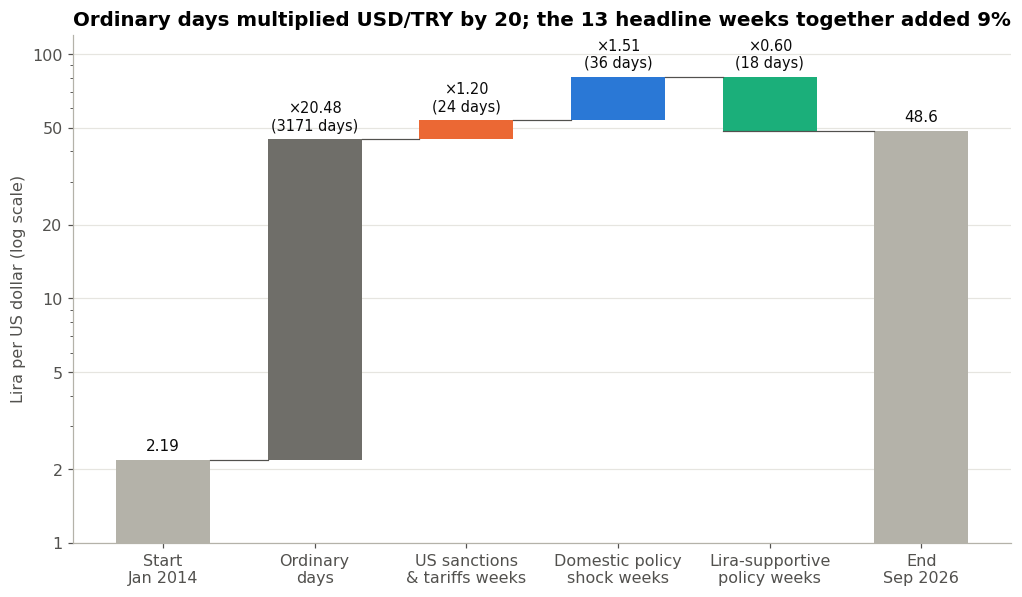

In [15]:
labels = [f"Start\n{df.index[0]:%b %Y}", "Ordinary\ndays", "US sanctions\n& tariffs weeks",
          "Domestic policy\nshock weeks", "Lira-supportive\npolicy weeks", f"End\n{df.index[-1]:%b %Y}"]
levels = [start_px]
for s in steps:
    levels.append(levels[-1] * decomp.loc[s, "multiplier"])
colors = ["#b4b2a9"] + [COLORS.get(s, "#6f6e69") for s in steps] + ["#b4b2a9"]

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_yscale("log")
ax.bar(0, start_px - 1, color=colors[0], width=0.62, bottom=1)
for i, s in enumerate(steps, start=1):
    lo, hi = sorted([levels[i - 1], levels[i]])
    ax.bar(i, hi - lo, bottom=lo, color=colors[i], width=0.62)
    ax.plot([i - 1 + 0.31, i - 0.31], [levels[i - 1]] * 2, color=INK2, lw=0.8)
    ax.text(i, hi * 1.06, f"×{decomp.loc[s, 'multiplier']:.2f}\n({decomp.loc[s, 'days']} days)",
            ha="center", va="bottom", fontsize=9.5, color=INK)
ax.plot([len(steps) - 0.31, len(steps) + 1 - 0.31], [levels[-1]] * 2, color=INK2, lw=0.8)
ax.bar(len(steps) + 1, end_px - 1, bottom=1, color=colors[-1], width=0.62)
ax.text(0, start_px * 1.06, f"{start_px:.2f}", ha="center", va="bottom", fontsize=10, color=INK)
ax.text(len(steps) + 1, end_px * 1.06, f"{end_px:.1f}", ha="center", va="bottom", fontsize=10, color=INK)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_ylim(1, 120)
ax.set_yticks([1, 2, 5, 10, 20, 50, 100])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_ylabel("Lira per US dollar (log scale)")
ax.grid(axis="x", visible=False)
ax.set_title(f"Ordinary days multiplied USD/TRY by {decomp.loc['Ordinary days', 'multiplier']:.0f}; "
             f"the {len(events)} headline weeks together added {headline_net - 1:.0%}")
fig.savefig(FIG_DIR / "05_crash_vs_grind.png")
plt.show()

## 11. Fat tails: why normal-distribution risk models fail here

Many simple risk models (for example parametric Value-at-Risk) assume daily returns are normally distributed. If they were, a move more than 4 standard deviations from the mean would happen about once every 60 years of trading days. The table counts how often it actually happened.

In [16]:
z = (r - r.mean()) / r.std()
tails = pd.DataFrame({"threshold": [3, 4, 5, 6, 10]})
tails["observed_days"] = [(z.abs() > k).sum() for k in tails["threshold"]]
tails["expected_if_normal"] = [len(r) * 2 * stats.norm.sf(k) for k in tails["threshold"]]
tails["ratio"] = tails["observed_days"] / tails["expected_if_normal"]
print(f"{len(r)} trading days | annualised vol {r.std() * np.sqrt(252):.0%} | "
      f"skew {stats.skew(r):.1f} | excess kurtosis {stats.kurtosis(r):.0f} (a normal distribution has 0)")
print(f"Excess kurtosis without the single largest day: {stats.kurtosis(r.drop(z.abs().idxmax())):.0f}\n")
print(tails.to_string(index=False, float_format=lambda v: f"{v:,.4g}"))

for label, day in [("Biggest lira fall", z.idxmax()), ("Biggest lira rise", z.idxmin())]:
    p = 2 * stats.norm.sf(abs(z[day]))
    print(f"\n{label}: {day.date()}, {np.expm1(r[day]):+.1%} in USD/TRY = {z[day]:+.1f} standard deviations.")
    print(f"  A normal model expects a day this extreme about once every {1 / (p * 252):.1e} years.")

3249 trading days | annualised vol 17% | skew -6.3 | excess kurtosis 246 (a normal distribution has 0)
Excess kurtosis without the single largest day: 42

 threshold  observed_days  expected_if_normal     ratio
         3             39               8.772     4.446
         4             22              0.2058     106.9
         5             13            0.001863     6,979
         6              8           6.411e-06 1.248e+06
        10              5           4.951e-20  1.01e+20

Biggest lira fall: 2018-08-13, +14.0% in USD/TRY = +12.2 standard deviations.
  A normal model expects a day this extreme about once every 9.9e+30 years.

Biggest lira rise: 2021-12-21, -26.7% in USD/TRY = -29.2 standard deviations.
  A normal model expects a day this extreme about once every 2.6e+184 years.


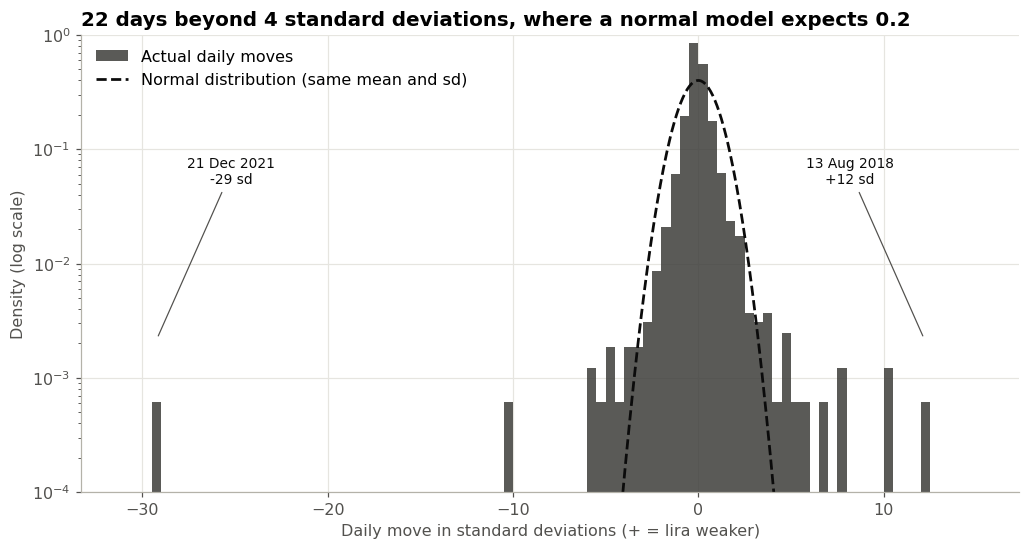

In [17]:
fig, ax = plt.subplots(figsize=(11, 5.4))
bins = np.arange(-31, 15, 0.5)
ax.hist(z, bins=bins, density=True, color=NEUTRAL, alpha=0.85, label="Actual daily moves")
xs = np.linspace(-31, 15, 800)
ax.plot(xs, stats.norm.pdf(xs), color=INK, lw=1.8, ls="--", label="Normal distribution (same mean and sd)")
ax.set_yscale("log")
ax.set_ylim(1e-4, 1)
ax.set_xlabel("Daily move in standard deviations (+ = lira weaker)")
ax.set_ylabel("Density (log scale)")
for day in [z.idxmax(), z.idxmin()]:
    ax.annotate(f"{day:%d %b %Y}\n{z[day]:+.0f} sd", xy=(z[day], 2.2e-3), xytext=(z[day] + (4 if z[day] < 0 else -4), 0.05),
                ha="center", fontsize=9, color=INK, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
n4 = int(tails.loc[tails['threshold'] == 4, 'observed_days'].iloc[0])
e4 = tails.loc[tails['threshold'] == 4, 'expected_if_normal'].iloc[0]
ax.set_title(f"{n4} days beyond 4 standard deviations, where a normal model expects {e4:.1f}")
ax.legend(loc="upper left")
fig.savefig(FIG_DIR / "06_fat_tails.png")
plt.show()

## 12. Interactive chart

The Plotly chart I started in my first version, finished: hover over any event marker for what happened and the abnormal move. (GitHub does not display interactive charts, so it is also saved as `figures/usdtry_interactive.html`, which opens in any browser.)

In [18]:
pfig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.7, 0.3], vertical_spacing=0.06,
                     subplot_titles=("USD/TRY (lira per dollar, log scale)", "21-day volatility (% a year)"))
pfig.add_trace(go.Scatter(x=df.index, y=df["Close"], mode="lines", name="USD/TRY",
                          line=dict(color=NEUTRAL, width=1.5), hovertemplate="%{x|%d %b %Y}: %{y:.3f}<extra></extra>"), 1, 1)
pfig.add_trace(go.Scatter(x=df.index, y=df["Volatility"] * 100, mode="lines", name="Volatility", showlegend=False,
                          line=dict(color=NEUTRAL, width=1.2), hovertemplate="%{x|%d %b %Y}: %{y:.0f}%<extra></extra>"), 2, 1)
for cat, grp in results.groupby("category"):
    level = df["Close"].reindex(grp["day0"]).values
    info = [f"<b>{s}</b><br>{d:%d %b %Y}<br>Days 0-1: {m1:+.1f}%<br>Days 0-60: {m60:+.1f}%"
            for s, d, m1, m60 in zip(grp["short"], grp["date"], grp["move_1"], grp["move_60"])]
    pfig.add_trace(go.Scatter(x=grp["day0"], y=level, mode="markers", name=cat, text=info,
                              marker=dict(color=COLORS[cat], size=11, line=dict(color="white", width=1.5)),
                              hovertemplate="%{text}<extra></extra>"), 1, 1)
pfig.update_yaxes(type="log", row=1, col=1)
pfig.update_layout(template="plotly_white", height=650, title="The Turkish lira and the 13 events, 2014 to 2026",
                   legend=dict(orientation="h", y=1.08, x=0))
pfig.write_html(FIG_DIR / "usdtry_interactive.html", include_plotlyjs="cdn")
pfig.show()

## 13. Conclusions

### Do sanctions crash currencies?

Not on their own, at least not in Turkey's case. US sanctions and tariffs produced one violent move and three near misses, and the violent one did not last. What decided whether a crash stuck was the **policy response**: when the central bank raised rates by 625bp in September 2018, the panic reversed; when policy-makers cut rates into 20% inflation in late 2021, the lira lost more than in 2018, with no sanctions involved at all. Sanctions work as an accelerant: they hurt most when they land on a currency that is already vulnerable (high inflation, negative real interest rates, a central bank that markets do not trust).

### Is the crash as bad as the headlines say?

Partly no, and partly worse. No, because headlines are written at the worst moment and often quote the dollar's rise rather than the lira's fall ("up 100%" is a 50% loss, not a 100% one). Worse, because the real damage came from the slow grind on ordinary days, which never makes the news: strip out every headline week and USD/TRY still rises from 2.19 to about 45.

### What this means for Iran

Turkey is a useful but imperfect analogue. Its sanctions were narrow (named officials, one defence agency, tariffs on metals) and its currency trades freely. Iran's sanctions are comprehensive and aimed at its main source of dollars, oil exports; the US and Israel attacked Iran on 28 February 2026 ([Business Today](https://businesstoday.in/world/story/2-million-rial-for-1-irans-currency-hits-historic-low-amid-fresh-us-sanctions-550978-2026-08-24)); and inflation was reported at 66% in July 2026, with the open-market rate passing 2 million rials per dollar in late August against about 958,000 a year earlier ([roic.ai](https://www.roic.ai/news/irans-rial-plunges-to-record-low-as-sanctions-and-inflation-bite-09-02-2026)). The Turkish evidence suggests that the rial's collapse should be read the same way: sanctions acting on an economy that already had high inflation and low policy credibility, now combined with war, rather than sanctions alone.

### What a trader could take from this

* Turkish sanctions headlines were, on average, **mean-reverting**; domestic credibility shocks were **trending**. The question to ask after a headline is "how will the central bank respond?", not "how bad is the headline?".
* **Volatility regime matters.** Since mid-2023 the lira's daily moves have been small and steady (21-day volatility mostly under 5% a year), so a 3.6% move after the March 2025 arrest of İmamoğlu was an 11-standard-deviation event relative to the previous year. The same percentage move means very different things in different regimes.
* **Tail risk is two-sided.** The largest single day in the sample was USD/TRY *falling* 27% (a 36% gain for the lira) after the KKM announcement, which would have been ruinous for anyone short the lira who sized the position with a normal-distribution risk model.

### Limitations

* **Small sample.** Four sanctions events cannot prove a general law; the result is a well-documented case study, not a theorem.
* **Overlapping windows.** The August and September 2018 events fall inside each other's 60-day windows, as do the November and December 2021 events. That is partly the point (the policy response is what reversed the shock), but it means the 60-day numbers are not independent.
* **Anticipation.** Some events were expected (the Brunson dispute had been building for weeks), so part of the move may have happened before day 0.
* **Simple model of "normal".** The constant-mean model ignores changing drift and volatility; estimation windows that contain earlier crises (2019 events, estimated on 2018 data) make later z-scores smaller.
* **One snapshot a day.** ECB fixings miss intraday extremes, and news that lands after the 14:10 CET fixing only shows up the next day (the KKM reaction, for example, appears in the 21 December fixing).
* **Spot only.** The analysis ignores carry: lira deposits paid high interest rates, which matters for anyone actually holding the currency.

### Next steps

1. Run the same event-study code on another sanctioned currency with clean data, such as the Russian rouble around the April 2018 US sanctions (the ECB published RUB rates until March 2022).
2. Add carry to measure total returns to a lira investor, not just the exchange rate.
3. A placebo test: run the event study on hundreds of random dates to see how unusual each CAR really is.
4. Add market-implied measures (FX options volatility, sovereign CDS) to see what traders expected before each event, not just what happened.

## Appendix: why I did not rely on a GARCH model

GARCH(1,1) is the standard model for volatility clustering: $\sigma^2_t = \omega + \alpha\,\varepsilon^2_{t-1} + \beta\,\sigma^2_{t-1}$. The sum $\alpha + \beta$ measures how persistent volatility shocks are, and the half-life of a shock is $\ln(0.5) / \ln(\alpha + \beta)$ days.

Fitted to the full 2014 to 2026 sample, it returns $\alpha + \beta \approx 1$: shocks that never decay. That is a known artefact. When a series switches between regimes (here, tightly managed calm in 2024 to 2026 versus chaos in 2021), a single GARCH model reads the regime shifts as infinitely persistent volatility. So I measured the decay event by event instead (section 8).

In [19]:
from arch import arch_model
garch = arch_model(r * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
a, b = garch.params["alpha[1]"], garch.params["beta[1]"]
print(garch.params.round(4))
print(f"\nalpha + beta = {a + b:.4f}  (1 means shocks never decay)")

mu          0.0500
omega       0.0006
alpha[1]    0.1782
beta[1]     0.8218
nu          4.2242
Name: params, dtype: float64

alpha + beta = 1.0000  (1 means shocks never decay)


In [20]:
# Save the results so the README numbers can be checked against them
out = results.drop(columns=["car_1", "car_5", "car_60"]).copy()
out["date"], out["day0"] = out["date"].dt.date, out["day0"].dt.date
out.round(3).to_csv(RESULTS_DIR / "event_study.csv", index=False)
decomp.round(4).to_csv(RESULTS_DIR / "decomposition.csv")
print("Saved:", sorted(p.name for p in RESULTS_DIR.iterdir()), sorted(p.name for p in FIG_DIR.iterdir()))

Saved: ['decomposition.csv', 'event_study.csv'] ['01_big_picture.png', '02_case_2018.png', '03_case_2021.png', '04_event_study.png', '05_crash_vs_grind.png', '06_fat_tails.png', 'usdtry_interactive.html']
